In [1]:
# ============================================================
# CELL 0: Configuration and Hyperparameters (unchanged, ART keys added)
# ============================================================
import os
# Reduce CUDA memory fragmentation (must be set before torch initializes its
# CUDA caching allocator, so this line stays first, before `import torch`).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import torch
import torch._utils  # noqa: F401
# Kaggle-environment compatibility fix: on some torch/torchvision builds,
# `torch._utils` is not yet bound as an attribute of `torch` at this point,
# even though torchvision's internal `torch._dynamo` import chain references
# `torch._utils._get_device_index` at MODULE IMPORT time. Without the
# explicit `import torch._utils` above, `from torchvision import transforms`
# in Cell 1 fails with:
#   AttributeError: module 'torch' has no attribute '_utils'
# This import must run before any torchvision import happens, so it stays
# here in Cell 0 rather than in Cell 1 (which must remain unchanged).

# Kaggle-environment fix, part 2: DataLoader worker processes (Cell 1 uses
# CONFIG["num_workers"] > 0) run in their OWN separate Python process. The
# `import torch._utils` fix above only patches THIS (main) process -- if
# Kaggle's multiprocessing default start method is "spawn" rather than
# "fork", each worker process re-imports torch from scratch in a brand-new
# interpreter that never runs this notebook's Cell 0, so it hits the exact
# same "AttributeError: module 'torch' has no attribute '_utils'" bug
# independently, deep inside torch/storage.py during batch collation. Best
# effort: force "fork" so workers inherit this process's already-fixed
# `torch` module instead of re-importing it.
import torch.multiprocessing as _mp
try:
    _mp.set_start_method("fork", force=True)
except RuntimeError:
    pass  # start method already set for this kernel session; safe to ignore

# --- CONFIGURATION & HYPERPARAMETERS ---
CONFIG = {
    # Dataset path on Kaggle (adjust if your dataset directory name differs)
    "data_root": "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23" , # Or your specific FF++ C23 directory path

    "seed": 42,
    
    # Dataset Slicing Control (Number of total videos to use: Real + Fake combined)
    # Set to e.g., 500 or 1000 for quick debugging, or None to use the full available set.
    "max_videos_to_use": None, 
    
    # Video Temporal Properties
    "seq_len": 16,            # Number of consecutive frames sampled per video
    "img_size": 224,          # Spatial resolution for EfficientNet-B1
    
    # Training Hyperparameters
    "batch_size": 8,          # Batch size (adjust based on Kaggle GPU VRAM: T4/P100)
    "num_epochs": 5,          # Number of training epochs
    "lr": 1e-4,               # Learning rate for AdamW optimizer
    "test_split": 0.15,       # Fraction of dataset reserved for test
    "val_split": 0.15,        # Fraction of datset reserved for validation

    # Preprocessing
    "compression_prob": 0.5,
    
    # System
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    "num_workers": 0,          # DataLoader worker threads -- forced to 0 (was 3).
                               # See the Kaggle-environment fix note above: this
                               # environment's DataLoader worker processes hit
                               # "AttributeError: module 'torch' has no attribute
                               # '_utils'" independently of the main process, which
                               # forcing num_workers=0 sidesteps entirely by loading
                               # data in-process (no worker subprocess is created at
                               # all). If you've confirmed the `fork` start-method
                               # fix above resolves it for your session, you can try
                               # raising this back toward 3 for faster data loading.

    # ------------------------------------------------------------------
    # ADVERSARIAL ROBUSTNESS TRAINING (ART) CONFIGURATION [NEW]
    # ------------------------------------------------------------------
    "adv_training": True,              # Master switch for adversarial training
    "adv_method": "FGSM",              # Attack used DURING training (fast, practical on Kaggle GPU)
    "epsilon": 4 / 255,                # Perturbation budget in PIXEL space (standard 8-bit image scale)
    "adv_alpha": 1 / 255,              # PGD step size in PIXEL space
    "adv_steps": 3,                    # PGD steps used for evaluation-only attacks
    "adv_loss_weight": 0.5,            # Weight given to adversarial loss vs clean loss
    "adv_eval_epsilon": 4 / 255,       # Default epsilon used for robustness evaluation
    "save_adv_checkpoint": "/kaggle/working/ffpp_video_art_detector.pth",
    "save_clean_checkpoint": "/kaggle/working/ffpp_video_clean_baseline.pth",

    # If you still hit CUDA OOM after the memory fixes in Cells 4-5, the
    # single safest lever left (per the brief: "do not change batch_size
    # unless necessary for CUDA memory") is to lower this value, e.g. to 4.
    "adv_train_batch_size_fallback": 4,
}

print(f"Using device: {CONFIG['device']}")
print(f"Adversarial training enabled: {CONFIG['adv_training']} | method: {CONFIG['adv_method']} | epsilon(px): {CONFIG['epsilon']:.4f}")


Using device: cuda
Adversarial training enabled: True | method: FGSM | epsilon(px): 0.0157


In [2]:
# ============================================================
# CELL 1: Dataset + preprocessing + DataLoaders [UNCHANGED]
# ============================================================
import os
import cv2
import random
import numpy as np
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from tqdm.notebook import tqdm


def apply_social_media_compression(img):
    """
    Simulates aggressive social media pipeline: 
    Downscale -> Chroma Subsampling (JPEG) -> Gaussian Blur -> Upscale
    """
    h, w, _ = img.shape
    
    # Step 1: Aggressive Downscaling (mimicking platform resizing)
    scale_factor = random.uniform(1.0, 1.0)
    new_h, new_w = int(h * scale_factor), int(w * scale_factor)
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Step 2: Apply a mild Gaussian Blur
    if random.random() < 0.7:
        img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
        
    # Step 3: Extreme JPEG Compression with Chroma Subsampling
    quality = random.randint(10, 25)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    
    # Convert to RGB for PIL / PyTorch
    return decimg


class PreextractedVideoDataset(Dataset):
    """
    Dataset that loads pre-extracted static image frames from disk, 
    completely eliminating MP4 decoding overhead during training.
    """
    def __init__(self, sample_records, seq_len=8, img_size=224, is_train=True):
        self.sample_records = sample_records # List of (folder_path, label)
        self.seq_len = seq_len
        self.img_size = img_size
        self.is_train = is_train
        self.rng = random.Random(CONFIG['seed'])

    def __len__(self):
        return len(self.sample_records)

    def __getitem__(self, idx):
        folder_path, label = self.sample_records[idx]
        folder = Path(folder_path)
        
        # Gather all extracted frame files in this video's directory
        frame_files = sorted(list(folder.glob("*.jpg")))

        # Create a local video-specific random generator seeded by the folder name string.
        # This guarantees every call for the same video produces the identical sequence of random choices.
        video_seed = abs(hash(str(folder))) % (2**32)
        vid_rng = random.Random(video_seed)

        should_compress = self.is_train and vid_rng.random() < CONFIG['compression_prob']
        compress_quality = vid_rng.randint(10, 25) if should_compress else None
        should_blur = vid_rng.random() < 0.7 if should_compress else False
        scale_factor = vid_rng.uniform(0.85, 1.0)
        
        if self.is_train:
            do_flip = vid_rng.random() < 0.5
            rotation_angle = vid_rng.uniform(-15, 15)
            brightness_factor = vid_rng.uniform(0.8, 1.2)
            contrast_factor = vid_rng.uniform(0.8, 1.2)
            saturation_factor = vid_rng.uniform(0.9, 1.1)
            hue_factor = vid_rng.uniform(-0.05, 0.05)
            
            # Simulate RandomCrop with padding=4 and reflect mode
            crop_padding = 4
            crop_top = vid_rng.randint(0, 2 * crop_padding)
            crop_left = vid_rng.randint(0, 2 * crop_padding)
            
        processed_frames = []
        for f_path in frame_files[:self.seq_len]:
            # Read image using OpenCV and convert BGR to RGB PIL Image
            img = cv2.imread(str(f_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            if should_compress:  
                # Apply the exact same compression parameters to every frame in this video
                h, w, _ = img_rgb.shape
                new_h, new_w = int(h * scale_factor), int(w * scale_factor)
                img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
                img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
                
                if should_blur:
                    img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
                    
                encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), compress_quality]
                _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
                img_rgb = cv2.imdecode(encimg, 1)
            
            pil_img = transforms.ToPILImage()(img_rgb)
            
            pil_img = TF.resize(pil_img, (self.img_size, self.img_size))
                
            if self.is_train:
                pil_img = TF.rotate(pil_img, rotation_angle)
                pil_img = TF.pad(pil_img, padding=crop_padding, padding_mode='reflect')
                pil_img = TF.crop(pil_img, top=crop_top, left=crop_left, height=self.img_size, width=self.img_size)
                
                if do_flip:
                    pil_img = TF.hflip(pil_img)
                    
                pil_img = TF.adjust_brightness(pil_img, brightness_factor)
                pil_img = TF.adjust_contrast(pil_img, contrast_factor)
                pil_img = TF.adjust_hue(pil_img, hue_factor)
                pil_img = TF.adjust_saturation(pil_img, saturation_factor)
            
            tensor_frame = TF.to_tensor(pil_img)
            tensor_frame = TF.normalize(tensor_frame, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            processed_frames.append(tensor_frame)
            
        # Fallback padding if frames are missing
        while len(processed_frames) < self.seq_len:
            if len(processed_frames) > 0:
                processed_frames.append(processed_frames[-1].clone())
            else:
                processed_frames.append(torch.zeros(3, self.img_size, self.img_size))
                
        video_tensor = torch.stack(processed_frames[:self.seq_len])
        label_tensor = torch.tensor(label, dtype=torch.float32)
        
        return video_tensor, label_tensor


def extract_videos_to_disk(data_root, output_dir="/kaggle/working/extracted_frames", max_videos=None, seq_len=8):
    """
    One-time pre-processor: Unpacks MP4 videos into static JPEG frames 
    on Kaggle's local scratch disk.
    """
    root_path = Path(data_root)
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)
    
    real_folders = ["original", "Original", "real"]
    fake_folders = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
    
    real_videos, fake_videos = [], []
    for rf in real_folders:
        r_path = root_path / rf
        if r_path.exists():
            real_videos.extend(list(r_path.glob("*.mp4")) + list(r_path.glob("*/*.mp4")))
            
    for ff in fake_folders:
        f_path = root_path / ff
        if f_path.exists():
            fake_videos.extend(list(f_path.glob("*.mp4")) + list(f_path.glob("*/*.mp4")))
            
    if max_videos is not None:
        half_limit = max_videos // 2
        real_videos = real_videos[:half_limit]
        fake_videos = fake_videos[:half_limit]
        
    records = []
    all_tasks = [(p, 0) for p in real_videos] + [(p, 1) for p in fake_videos]
    
    print(f"Pre-extracting {len(all_tasks)} videos to disk (this runs only once)...")
    for v_path_str, label in tqdm(all_tasks, desc="Extracting Frames"):
        v_path = Path(v_path_str)
        # Create a unique folder name for this video
        vid_out_dir = out_path / ("real" if label == 0 else "fake") / v_path.stem
        vid_out_dir.mkdir(parents=True, exist_ok=True)
        
        # Check if already extracted in a previous run
        existing_frames = list(vid_out_dir.glob("*.jpg"))
        if len(existing_frames) >= seq_len:
            records.append((str(vid_out_dir), label))
            continue
            
        cap = cv2.VideoCapture(str(v_path))
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        if total_frames >= seq_len:
            indices = np.linspace(0, total_frames - 1, seq_len, dtype=int)
        else:
            indices = np.arange(total_frames)
            
        curr_frame = 0
        target_indices = set(indices)
        saved_count = 0
        
        while cap.isOpened() and saved_count < seq_len:
            ret, frame = cap.read()
            if not ret:
                break
            if curr_frame in target_indices:
                frame_path = vid_out_dir / f"frame_{saved_count:03d}.jpg"
                cv2.imwrite(str(frame_path), frame)
                saved_count += 1
            curr_frame += 1
        cap.release()
        
        if saved_count > 0:
            records.append((str(vid_out_dir), label))
            
    return records

# Execute extraction and build DataLoaders
extracted_records = extract_videos_to_disk(
    CONFIG["data_root"], 
    output_dir="/kaggle/working/extracted_frames", 
    max_videos=CONFIG["max_videos_to_use"], 
    seq_len=CONFIG["seq_len"]
)

if len(extracted_records) == 0:
    raise ValueError("No frames were extracted. Check your CONFIG['data_root'] path.")

# Get video ids from filename
groups = [Path(r[0]).stem.split('_')[0] for r in extracted_records]
labels = [r[1] for r in extracted_records]

# Split total records into (Train + Val) and Test
gss_test = GroupShuffleSplit(n_splits=1, test_size=CONFIG.get("test_split", 0.15), random_state=42)
train_val_idx, test_idx = next(gss_test.split(extracted_records, labels, groups=groups))

train_val_records = [extracted_records[i] for i in train_val_idx]
test_records = [extracted_records[i] for i in test_idx]
train_val_groups = [groups[i] for i in train_val_idx]
train_val_labels = [labels[i] for i in train_val_idx]

# Split the remaining data into Train and Validation
val_ratio_adjusted = CONFIG["val_split"] / (1.0 - CONFIG.get("test_split", 0.15))
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_ratio_adjusted, random_state=42)
train_idx, val_idx = next(gss_val.split(train_val_records, train_val_labels, groups=train_val_groups))

train_records = [train_val_records[i] for i in train_idx]
raw_val_records = [train_val_records[i] for i in val_idx]

# Balance validation records
val_real = [r for r in raw_val_records if r[1] == 0]
val_fake = [r for r in raw_val_records if r[1] == 1]
min_val_count = min(len(val_real), len(val_fake))

val_rng = random.Random(CONFIG.get('seed', 42))
val_rng.shuffle(val_real)
val_rng.shuffle(val_fake)

val_records = val_real[:min_val_count] + val_fake[:min_val_count]
val_rng.shuffle(val_records)

# Balance test records (Optional, but recommended for clean evaluation metrics)
test_real = [r for r in test_records if r[1] == 0]
test_fake = [r for r in test_records if r[1] == 1]
min_test_count = min(len(test_real), len(test_fake))

test_rng = random.Random(CONFIG.get('seed', 42))
test_rng.shuffle(test_real)
test_rng.shuffle(test_fake)

test_records = test_real[:min_test_count] + test_fake[:min_test_count]
test_rng.shuffle(test_records)

# Datasets and DataLoaders
train_dataset = PreextractedVideoDataset(train_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=True)
val_dataset = PreextractedVideoDataset(val_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False)
test_dataset = PreextractedVideoDataset(test_records, seq_len=CONFIG["seq_len"], img_size=CONFIG["img_size"], is_train=False)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=CONFIG["num_workers"], drop_last=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"], pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=CONFIG["num_workers"], pin_memory=True)

print(f"Setup complete! Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Pre-extracting 6000 videos to disk (this runs only once)...


Extracting Frames:   0%|          | 0/6000 [00:00<?, ?it/s]

Setup complete! Train batches: 525 | Val batches: 38 | Test batches: 38


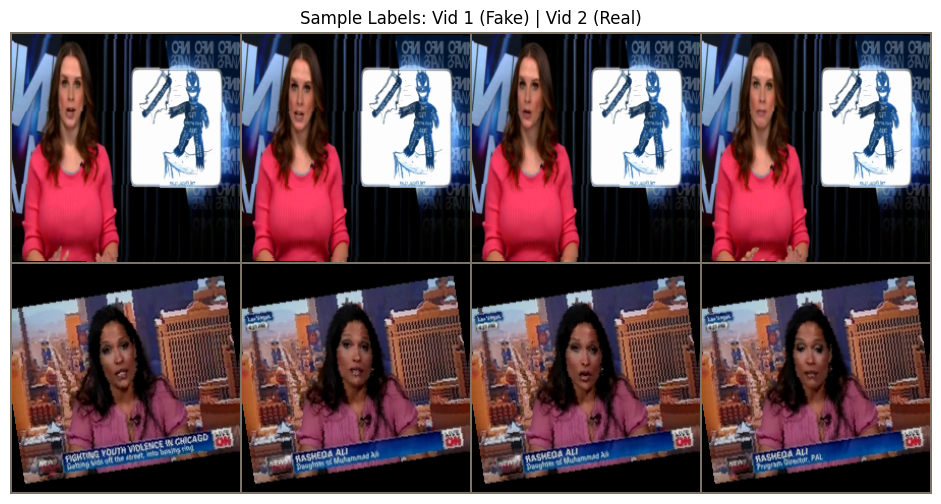

In [3]:
# ============================================================
# CELL 2: Dataset visualization [UNCHANGED]
# ============================================================
import matplotlib.pyplot as plt
import torch

images, labels = next(iter(train_loader))

# Extract 4 frames from the first video and 4 frames from the second video
video_1_frames = images[0, :4]  # Shape: [4, 3, 224, 224]
video_2_frames = images[1, :4]  # Shape: [4, 3, 224, 224]

# Combine them into a 4D tensor of 8 total images (4 per row when nrow=4)
images_to_show = torch.cat([video_1_frames, video_2_frames], dim=0)

out = make_grid(images_to_show, nrow=4)

# Unnormalize the grid tensor using ImageNet stats
mean = torch.tensor([0.485, 0.456, 0.406], device=out.device).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=out.device).view(3, 1, 1)
out_unnorm = torch.clamp(out * std + mean, 0.0, 1.0)

label_mapping = {0: "Real", 1: "Fake"}
label_1 = label_mapping[int(labels[0].item())]
label_2 = label_mapping[int(labels[1].item())]

# Create titles corresponding to each of the 8 frames (4 for video 1, 4 for video 2)
titles = f"Vid 1 ({label_1}) | Vid 2 ({label_2})"

# Convert the unnormalized PyTorch tensor from make_grid [C, H, W] to a NumPy array [H, W, C]
img_np = out_unnorm.permute(1, 2, 0).cpu().numpy()

# Use matplotlib directly to avoid OpenCV argument conflicts
plt.figure(figsize=(12, 6))
plt.imshow(img_np)
plt.title(f"Sample Labels: {titles}")
plt.axis("off")
plt.show()

In [4]:
# ============================================================
# CELL 3: EfficientNet-B1 + LSTM model [UNCHANGED]
# ============================================================
import torch
import torch._utils  # noqa: F401
# Kaggle-environment defensive guard (see Cell 0): if this kernel session
# was restarted (e.g. after an earlier CUDA OOM crash) and Cell 0 wasn't
# re-run first, `torch._utils` may not yet be bound as an attribute of
# `torch`, which makes `torch.hub`'s weight download below fail with
# "AttributeError: module 'torch' has no attribute '_utils'" while
# unpickling the pretrained EfficientNet-B1 checkpoint. This import is a
# harmless no-op if Cell 0 already ran. It does not change the model
# architecture below in any way.
import torch.nn as nn
from torchvision.models import efficientnet_b1, EfficientNet_B1_Weights

class FFPPDeepfakeDetector(nn.Module):
    def __init__(self, lstm_hidden_size=512, num_layers=2, dropout=0.4):
        super(FFPPDeepfakeDetector, self).__init__()
        
        # Spatial Feature Extractor
        weights = EfficientNet_B1_Weights.DEFAULT
        base_model = efficientnet_b1(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-1])
        self.dropout_cnn = nn.Dropout(p=dropout)
        self.flatten = nn.Flatten()
        self.feature_dim = 1280
        
        # Temporal Sequence Network
        self.lstm = nn.LSTM(
            input_size=self.feature_dim,
            hidden_size=lstm_hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        
        # Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        batch_size, seq_len, c, h, w = x.shape
        x = x.view(batch_size * seq_len, c, h, w)
        
        features = self.feature_extractor(x)
        features = self.flatten(features)
        features = self.dropout_cnn(features)
        
        features = features.view(batch_size, seq_len, self.feature_dim)
        lstm_out, _ = self.lstm(features)
        
        last_timestep_features = torch.mean(lstm_out, dim=1)
        out = self.classifier(last_timestep_features)
        return out.squeeze(1)

model = FFPPDeepfakeDetector().to(CONFIG["device"])
print("Model initialized successfully and moved to device.")

Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 172MB/s]


Model initialized successfully and moved to device.


In [5]:
# ============================================================
# CELL 4: ADVERSARIAL ATTACK FUNCTIONS (FGSM + PGD) [NEW]
# ============================================================
#
# The dataset already returns ImageNet-normalized video tensors of shape
# [B, T, 3, 224, 224]. All attacks below operate directly on that
# normalized tensor and perturb every frame of every video consistently.
#
# Because the tensors are normalized, an epsilon specified in pixel space
# (e.g. 4/255) does NOT correspond to the same epsilon in normalized space.
# We convert per-channel using the ImageNet std:
#
#     epsilon_normalized[c] = epsilon_pixel / std[c]
#     alpha_normalized[c]   = alpha_pixel   / std[c]
#
# MEMORY NOTE (fixes CUDA OOM seen at ~14.5/14.56 GiB on the first batch):
# With seq_len=16, a single forward pass already pushes batch_size*seq_len
# (e.g. 8*16=128) images through EfficientNet-B1 at once. The attack's
# forward pass previously ran in full FP32 (no autocast), which uses
# roughly 2x the activation memory of the FP16 forward pass used
# everywhere else in the notebook. That FP32 attack graph, combined with
# holding a second full graph for training right after it, is what
# exhausted the GPU. The attacks below now run under the SAME autocast
# policy as the rest of the pipeline. Autograd still produces a correct
# (FP32) gradient for the FP32 leaf input `x` even though the forward
# math runs in FP16 -- this is the same mechanism PyTorch AMP already
# relies on for parameter gradients. The only trade-off is that a
# vanishingly small number of FP16-underflowed gradient entries may end
# up with a zero sign (a slightly weaker, not incorrect, perturbation at
# those pixels) -- acceptable for FGSM/PGD, which only use the sign.

import torch
import torch.nn as nn

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)


def _prepare_model_for_attack(model):
    prev_modes = {m: m.training for m in model.modules()}
    model.eval()
    
    for m in model.modules():
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
            m.train()
            # Temporarily disable dropout to ensure deterministic gradients
            m._stored_dropout = m.dropout 
            m.dropout = 0.0
            
    return prev_modes

def _restore_model_modes(model, prev_modes):
    for m in model.modules():
        if m in prev_modes:
            m.train(prev_modes[m])
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)) and hasattr(m, '_stored_dropout'):
            m.dropout = m._stored_dropout
            del m._stored_dropout

def _get_norm_bounds(device):
    """Returns per-channel min/max of the normalized input space (i.e. the
    normalized values that correspond to raw pixel values 0 and 1)."""
    mean = IMAGENET_MEAN.to(device)
    std = IMAGENET_STD.to(device)
    valid_min = (0.0 - mean) / std
    valid_max = (1.0 - mean) / std
    return valid_min, valid_max


def _epsilon_to_normalized(epsilon_pixel, device):
    """Converts a scalar pixel-space epsilon into a per-channel normalized-space
    tensor of shape [1, 1, 3, 1, 1] broadcastable against [B, T, C, H, W]."""
    std = IMAGENET_STD.to(device)
    return epsilon_pixel / std


def fgsm_attack(model, videos, labels, epsilon, criterion=None, use_amp=None):
    """
    Fast Gradient Sign Method, applied over the COMPLETE video tensor
    [B, T, C, H, W]. Every frame of a given video is perturbed with the
    same-sign gradient step (i.e. the whole clip is attacked jointly,
    since the gradient already flows through all T frames via the LSTM).

    Args:
        model: FFPPDeepfakeDetector (or any model with matching forward signature)
        videos: clean input tensor [B, T, C, H, W], ImageNet-normalized, NOT requiring grad
        labels: ground-truth labels [B]
        epsilon: perturbation budget in PIXEL space (e.g. 4/255)
        criterion: loss function (defaults to BCEWithLogitsLoss)
        use_amp: whether to run the internal forward pass under autocast
                 (defaults to the global USE_AMP flag set in Cell 5 if available,
                 otherwise True when on CUDA)

    Returns:
        adv_videos: adversarially perturbed video tensor, detached, same shape as `videos`
    """
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()

    device = videos.device
    if use_amp is None:
        use_amp = globals().get("USE_AMP", device.type == "cuda")

    # Freeze BatchNorm/Dropout for attack generation, but keep any LSTM/GRU/RNN
    # submodule in train() mode so cuDNN's RNN backward kernel is available
    # (see _prepare_model_for_attack docstring above).
    prev_modes = _prepare_model_for_attack(model)

    # Work on a fresh leaf tensor that requires grad; never mutate `videos` in-place.
    x = videos.clone().detach().to(device)
    x.requires_grad_(True)

    if use_amp:
        temp_scaler = torch.amp.GradScaler('cuda')
        with torch.amp.autocast("cuda"):
            logits = model(x)
            loss = criterion(logits, labels)
            
        # Scale loss before computing gradients to prevent FP16 underflow
        scaled_grad = torch.autograd.grad(temp_scaler.scale(loss), x, retain_graph=False, create_graph=False)[0]
        # Unscale the gradients back to normal magnitude before taking the sign
        grad = scaled_grad / temp_scaler.get_scale()
    else:
        logits = model(x)
        loss = criterion(logits, labels)
        grad = torch.autograd.grad(loss, x, retain_graph=False, create_graph=False)[0]
        
    epsilon_norm = _epsilon_to_normalized(epsilon, device)  # [1,1,3,1,1]
    valid_min, valid_max = _get_norm_bounds(device)

    with torch.no_grad():
        x_adv = x + epsilon_norm * grad.sign()
        # Project the perturbation back into the epsilon ball around the clean input
        perturbation = torch.clamp(x_adv - videos, min=-epsilon_norm, max=epsilon_norm)
        x_adv = videos + perturbation
        # Keep the adversarial example within the valid (un-normalized 0..1 pixel) range
        x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)

    x_adv = x_adv.detach()

    # Clear any residual grads accumulated on model parameters during the backward call,
    # and drop references to the (now unneeded) forward/backward graph promptly.
    model.zero_grad(set_to_none=True)
    del x, logits, loss, grad

    _restore_model_modes(model, prev_modes)

    return x_adv


def pgd_attack(model, videos, labels, epsilon, alpha, steps, criterion=None,
                random_start=True, use_amp=None):
    """
    Projected Gradient Descent attack over the COMPLETE video tensor
    [B, T, C, H, W]. Used ONLY for stronger robustness evaluation
    (never for training, to keep Kaggle runtime practical).

    Args:
        model: FFPPDeepfakeDetector
        videos: clean input tensor [B, T, C, H, W], ImageNet-normalized
        labels: ground-truth labels [B]
        epsilon: perturbation budget in PIXEL space
        alpha: per-step size in PIXEL space
        steps: number of PGD iterations
        criterion: loss function (defaults to BCEWithLogitsLoss)
        random_start: if True, initializes with a small random perturbation inside the epsilon ball
        use_amp: whether to run each step's forward pass under autocast (see fgsm_attack)

    Returns:
        adv_videos: adversarially perturbed video tensor, detached, same shape as `videos`
    """
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()

    device = videos.device
    if use_amp is None:
        use_amp = globals().get("USE_AMP", device.type == "cuda")

    # Same reasoning as fgsm_attack: freeze BatchNorm/Dropout but force any
    # LSTM/GRU/RNN submodule to stay in train() mode so cuDNN's RNN backward
    # kernel is available for each of the PGD steps below.
    prev_modes = _prepare_model_for_attack(model)

    epsilon_norm = _epsilon_to_normalized(epsilon, device)   # [1,1,3,1,1]
    alpha_norm = _epsilon_to_normalized(alpha, device)       # [1,1,3,1,1]
    valid_min, valid_max = _get_norm_bounds(device)

    videos_clean = videos.clone().detach()

    if random_start:
        rand_noise = (torch.rand_like(videos_clean) * 2 - 1) * epsilon_norm
        x_adv = videos_clean + rand_noise
        x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)
    else:
        x_adv = videos_clean.clone()

    for _ in range(steps):
        x_adv = x_adv.detach()
        x_adv.requires_grad_(True)

        if use_amp:
            temp_scaler = torch.amp.GradScaler('cuda')
            with torch.amp.autocast("cuda"):
                logits = model(x_adv)
                loss = criterion(logits, labels)
                
            # Scale and unscale to prevent underflow
            scaled_grad = torch.autograd.grad(temp_scaler.scale(loss), x_adv, retain_graph=False, create_graph=False)[0]
            grad = scaled_grad / temp_scaler.get_scale()
        else:
            logits = model(x_adv)
            loss = criterion(logits, labels)
            grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]
            
        with torch.no_grad():
            x_adv = x_adv + alpha_norm * grad.sign()
            # Project back into the epsilon ball around the ORIGINAL clean input
            perturbation = torch.clamp(x_adv - videos_clean, min=-epsilon_norm, max=epsilon_norm)
            x_adv = videos_clean + perturbation
            x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)

        del logits, loss, grad

    model.zero_grad(set_to_none=True)
    _restore_model_modes(model, prev_modes)

    return x_adv.detach()


print("Adversarial attack utilities ready: fgsm_attack(), pgd_attack()")




Adversarial attack utilities ready: fgsm_attack(), pgd_attack()


In [6]:
# ============================================================
# CELL 5: ADVERSARIAL TRAINING FUNCTION [NEW]
# ============================================================
#
# Trains on a combination of clean and FGSM-adversarial examples every batch.
#
# MEMORY NOTE (fixes CUDA OOM):
# The previous version computed clean_logits AND adv_logits (two full
# forward graphs) before calling .backward() ONCE on their combined loss.
# That means both graphs -- each already large at seq_len=16 -- had to
# stay resident in GPU memory at the same time, on top of the attack's
# own forward/backward pass. This version instead does two SEPARATE
# backward passes (clean, then adversarial), each scaled by its own loss
# weight and accumulated into the same .grad buffers before a single
# optimizer step. This way only one forward/backward graph exists in
# memory at any moment -- mathematically identical to the combined-loss
# version (gradients are linear), just far cheaper in peak memory.

import gc
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score
from tqdm.notebook import tqdm

USE_AMP = (CONFIG["device"].type == "cuda")

# How often (in batches) to proactively release cached-but-unused GPU
# memory back to the allocator. Doing this every batch adds overhead;
# doing it periodically helps fragmentation without hurting throughput.
EMPTY_CACHE_EVERY_N_BATCHES = 25


def train_epoch_adversarial(model, dataloader, criterion, optimizer, device,
                             epsilon, adv_loss_weight, scaler, use_amp=USE_AMP):
    """
    Runs one epoch of adversarial training (clean + FGSM combined loss).

    Returns a dict with: clean_loss, adv_loss, total_loss, clean_acc, adv_acc
    """
    model.train()

    running_clean_loss = 0.0
    running_adv_loss = 0.0
    running_total_loss = 0.0
    n_samples = 0

    clean_preds_all, adv_preds_all, labels_all = [], [], []

    loader = tqdm(dataloader, desc="ART Training", leave=False)

    for batch_idx, (videos, labels) in enumerate(loader):
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        batch_size = videos.size(0)

        # ------------------------------------------------------------
        # STEP 1: Generate adversarial examples (input-only gradients).
        # This must NOT run under torch.no_grad(); fgsm_attack() manages
        # its own autograd context internally (under autocast, matching
        # the rest of the pipeline) and returns a detached tensor, so its
        # forward/backward graph is fully released before Step 2 begins.
        # ------------------------------------------------------------
        adv_videos = fgsm_attack(
            model, videos, labels,
            epsilon=epsilon,
            criterion=criterion,
            use_amp=use_amp,
        )

        # ------------------------------------------------------------
        # STEP 2: Clean, then adversarial training pass -- SEQUENTIALLY,
        # each with its own forward + backward, so only one graph is ever
        # resident in memory. Gradients accumulate into optimizer.grad
        # across both backward() calls; optimizer.step() applies them
        # together, so this is numerically equivalent to backpropagating
        # the combined loss in one shot.
        # ------------------------------------------------------------
        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast("cuda"):
                clean_logits = model(videos)
                clean_loss = criterion(clean_logits, labels)
            scaler.scale((1 - adv_loss_weight) * clean_loss).backward()

            with torch.amp.autocast("cuda"):
                adv_logits = model(adv_videos)
                adv_loss = criterion(adv_logits, labels)
            scaler.scale(adv_loss_weight * adv_loss).backward()

            scaler.step(optimizer)
            scaler.update()
        else:
            clean_logits = model(videos)
            clean_loss = criterion(clean_logits, labels)
            ((1 - adv_loss_weight) * clean_loss).backward()

            adv_logits = model(adv_videos)
            adv_loss = criterion(adv_logits, labels)
            (adv_loss_weight * adv_loss).backward()

            optimizer.step()

        total_loss_value = (1 - adv_loss_weight) * clean_loss.item() + adv_loss_weight * adv_loss.item()

        # ------------------------------------------------------------
        # Bookkeeping
        # ------------------------------------------------------------
        running_clean_loss += clean_loss.item() * batch_size
        running_adv_loss += adv_loss.item() * batch_size
        running_total_loss += total_loss_value * batch_size
        n_samples += batch_size

        clean_preds_all.extend(torch.sigmoid(clean_logits).detach().cpu().numpy())
        adv_preds_all.extend(torch.sigmoid(adv_logits).detach().cpu().numpy())
        labels_all.extend(labels.detach().cpu().numpy())

        # Explicitly free per-batch tensors/graphs to avoid accumulating
        # unnecessary memory across iterations.
        del adv_videos, clean_logits, adv_logits, clean_loss, adv_loss

        if (batch_idx + 1) % EMPTY_CACHE_EVERY_N_BATCHES == 0:
            gc.collect()
            torch.cuda.empty_cache()

    clean_preds_bin = (np.array(clean_preds_all) >= 0.5).astype(int)
    adv_preds_bin = (np.array(adv_preds_all) >= 0.5).astype(int)

    metrics = {
        "clean_loss": running_clean_loss / n_samples,
        "adv_loss": running_adv_loss / n_samples,
        "total_loss": running_total_loss / n_samples,
        "clean_acc": accuracy_score(labels_all, clean_preds_bin),
        "adv_acc": accuracy_score(labels_all, adv_preds_bin),
    }
    return metrics


print("Adversarial training function ready: train_epoch_adversarial()")


Adversarial training function ready: train_epoch_adversarial()


In [7]:
# ============================================================
# CELL 6: CLEAN + ADVERSARIAL VALIDATION [NEW]
# ============================================================
#
# Evaluates the model on CLEAN validation videos and on FGSM-attacked
# validation videos. Validation/test data is NEVER attacked outside of
# this dedicated evaluation function, and it is never used to update
# model weights.

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, roc_auc_score
from tqdm.notebook import tqdm


def _safe_roc_auc(labels, preds):
    try:
        return roc_auc_score(labels, preds)
    except ValueError:
        # Happens if a split only contains a single class
        return 0.0


def evaluate_clean_and_adversarial(model, dataloader, criterion, device,
                                    epsilon, use_amp=USE_AMP):
    """
    Runs clean AND FGSM-adversarial evaluation over `dataloader`.

    Returns a dict with:
        clean_loss, clean_acc, clean_roc_auc,
        adv_loss, adv_acc, adv_roc_auc,
        robustness_retention (adv_acc / clean_acc * 100)
    """
    model.eval()

    clean_loss_total, adv_loss_total, n_samples = 0.0, 0.0, 0
    clean_preds_all, adv_preds_all, labels_all = [], [], []

    loader = tqdm(dataloader, desc="Validating (clean + FGSM)", leave=False)

    for videos, labels in loader:
        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        batch_size = videos.size(0)

        # --- Clean evaluation (no gradients needed) ---
        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    clean_logits = model(videos)
                    clean_loss = criterion(clean_logits, labels)
            else:
                clean_logits = model(videos)
                clean_loss = criterion(clean_logits, labels)

        # --- FGSM adversarial evaluation (attack needs gradients internally) ---
        adv_videos = fgsm_attack(model, videos, labels, epsilon=epsilon, criterion=criterion, use_amp=use_amp)

        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    adv_logits = model(adv_videos)
                    adv_loss = criterion(adv_logits, labels)
            else:
                adv_logits = model(adv_videos)
                adv_loss = criterion(adv_logits, labels)

        clean_loss_total += clean_loss.item() * batch_size
        adv_loss_total += adv_loss.item() * batch_size
        n_samples += batch_size

        clean_preds_all.extend(torch.sigmoid(clean_logits).cpu().numpy())
        adv_preds_all.extend(torch.sigmoid(adv_logits).cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

        del adv_videos

    labels_arr = np.array(labels_all).astype(int)
    clean_preds_arr = np.array(clean_preds_all)
    adv_preds_arr = np.array(adv_preds_all)

    clean_bin = (clean_preds_arr >= 0.5).astype(int)
    adv_bin = (adv_preds_arr >= 0.5).astype(int)

    clean_acc = accuracy_score(labels_arr, clean_bin)
    adv_acc = accuracy_score(labels_arr, adv_bin)

    results = {
        "clean_loss": clean_loss_total / n_samples,
        "clean_acc": clean_acc,
        "clean_roc_auc": _safe_roc_auc(labels_arr, clean_preds_arr),
        "adv_loss": adv_loss_total / n_samples,
        "adv_acc": adv_acc,
        "adv_roc_auc": _safe_roc_auc(labels_arr, adv_preds_arr),
        "robustness_retention": (adv_acc / clean_acc * 100.0) if clean_acc > 0 else 0.0,
    }
    return results


def print_validation_results(results):
    print("Validation Results")
    print("------------------")
    print(f"Clean Accuracy       : {results['clean_acc']:.4f}")
    print(f"Clean ROC-AUC        : {results['clean_roc_auc']:.4f}")
    print(f"FGSM Accuracy        : {results['adv_acc']:.4f}")
    print(f"FGSM ROC-AUC         : {results['adv_roc_auc']:.4f}")
    print(f"Robustness Retention: {results['robustness_retention']:.2f}%")


print("Validation function ready: evaluate_clean_and_adversarial()")


Validation function ready: evaluate_clean_and_adversarial()


In [8]:
# ============================================================
# CELL 7: ART TRAINING EXECUTION [NEW]
# ============================================================

import torch
import torch.nn as nn

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=1e-3)
scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

best_adv_acc = None
best_clean_acc_at_best_adv = None

art_history = []

print("=" * 50)
print("ART TRAINING")
print("=" * 50)

for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch + 1}/{CONFIG['num_epochs']}")

    # ---- Train on clean + FGSM adversarial batches ----
    train_metrics = train_epoch_adversarial(
        model, train_loader, criterion, optimizer, CONFIG["device"],
        epsilon=CONFIG["epsilon"],
        adv_loss_weight=CONFIG["adv_loss_weight"],
        scaler=scaler,
        use_amp=USE_AMP,
    )

    print("\nTraining:")
    print(f"Clean Loss: {train_metrics['clean_loss']:.4f}")
    print(f"Adv Loss: {train_metrics['adv_loss']:.4f}")
    print(f"Total Loss: {train_metrics['total_loss']:.4f}")
    print(f"Clean Acc: {train_metrics['clean_acc']:.4f}")
    print(f"Adv Acc: {train_metrics['adv_acc']:.4f}")

    # ---- Validate on clean + FGSM adversarial validation set ----
    val_metrics = evaluate_clean_and_adversarial(
        model, val_loader, criterion, CONFIG["device"],
        epsilon=CONFIG["adv_eval_epsilon"],
        use_amp=USE_AMP,
    )

    print("\nValidation:")
    print(f"Clean Acc: {val_metrics['clean_acc']:.4f}")
    print(f"Clean ROC-AUC: {val_metrics['clean_roc_auc']:.4f}")
    print(f"FGSM Acc: {val_metrics['adv_acc']:.4f}")
    print(f"FGSM ROC-AUC: {val_metrics['adv_roc_auc']:.4f}")

    art_history.append({"epoch": epoch + 1, **train_metrics, **val_metrics})

    # ---- Checkpoint selection: prefer best ADVERSARIAL validation accuracy ----
    if best_adv_acc is None or val_metrics["adv_acc"] > best_adv_acc:
        best_adv_acc = val_metrics["adv_acc"]
        best_clean_acc_at_best_adv = val_metrics["clean_acc"]
        torch.save(model.state_dict(), CONFIG["save_adv_checkpoint"])
        print("\nBest ART model saved.")

    print("-" * 50)

# ---- Also persist a clean baseline checkpoint (final-epoch weights) ----
torch.save(model.state_dict(), CONFIG["save_clean_checkpoint"])

print("\nART training complete!")
print(f"Best FGSM validation accuracy : {best_adv_acc:.4f}")
print(f"Clean validation accuracy at that checkpoint: {best_clean_acc_at_best_adv:.4f}")
print(f"Best ART checkpoint saved to: {CONFIG['save_adv_checkpoint']}")
print(f"Clean baseline checkpoint saved to: {CONFIG['save_clean_checkpoint']}")


ART TRAINING

Epoch 1/5


ART Training:   0%|          | 0/525 [00:00<?, ?it/s]


Training:
Clean Loss: 0.4713
Adv Loss: 0.4794
Total Loss: 0.4754
Clean Acc: 0.8248
Adv Acc: 0.8221


Validating (clean + FGSM):   0%|          | 0/38 [00:00<?, ?it/s]


Validation:
Clean Acc: 0.5000
Clean ROC-AUC: 0.5438
FGSM Acc: 0.5000
FGSM ROC-AUC: 0.0922

Best ART model saved.
--------------------------------------------------

Epoch 2/5


...


Validation:
Clean Acc: 0.5000
Clean ROC-AUC: 0.5756
FGSM Acc: 0.5000
FGSM ROC-AUC: 0.2676
--------------------------------------------------

Epoch 5/5


ART Training:   0%|          | 0/525 [00:00<?, ?it/s]


Training:
Clean Loss: 0.4540
Adv Loss: 0.4554
Total Loss: 0.4547
Clean Acc: 0.8333
Adv Acc: 0.8333


Validating (clean + FGSM):   0%|          | 0/38 [00:00<?, ?it/s]


Validation:
Clean Acc: 0.5000
Clean ROC-AUC: 0.5586
FGSM Acc: 0.5000
FGSM ROC-AUC: 0.5032
--------------------------------------------------

ART training complete!
Best FGSM validation accuracy : 0.5000
Clean validation accuracy at that checkpoint: 0.5000
Best ART checkpoint saved to: /kaggle/working/ffpp_video_art_detector.pth
Clean baseline checkpoint saved to: /kaggle/working/ffpp_video_clean_baseline.pth


In [9]:
# ============================================================
# CELL 8: LOAD BEST ART MODEL [NEW]
# ============================================================
#
# MEMORY NOTE (fixes the CUDA OOM seen here):
# At this point, Cell 7's `optimizer` (AdamW keeps momentum + variance
# buffers roughly the same size as the model's own parameters) and
# `scaler` are still alive and still holding GPU memory. Instantiating a
# SECOND fresh `FFPPDeepfakeDetector()` here -- as a naive "load the best
# model" cell would -- means two full sets of EfficientNet-B1 + LSTM
# weights plus the optimizer state all exist on the GPU simultaneously,
# which is what exhausted the 14.56 GiB budget. This version frees the
# now-unneeded optimizer/scaler first, then loads the checkpoint IN PLACE
# into the existing `model` object from Cell 3/7 instead of creating a
# new one.

import gc
import torch

# Free the optimizer and GradScaler from the ART training loop -- they are
# no longer needed now that training is finished, but nothing earlier in
# the notebook drops them explicitly.
for _name in ("optimizer", "scaler"):
    if _name in globals():
        del globals()[_name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if "model" in globals():
    # Reuse the existing model object: load the best checkpoint's weights
    # in place rather than constructing a second FFPPDeepfakeDetector.
    model.load_state_dict(torch.load(CONFIG["save_adv_checkpoint"], map_location=CONFIG["device"]))
else:
    # Fallback for a fresh/standalone run where Cell 3 hasn't executed.
    model = FFPPDeepfakeDetector().to(CONFIG["device"])
    model.load_state_dict(torch.load(CONFIG["save_adv_checkpoint"], map_location=CONFIG["device"]))

model.eval()

print("Best adversarially trained model loaded successfully.")


Best adversarially trained model loaded successfully.


FINAL CLEAN TEST EVALUATION (ART-Trained Model)

ROC-AUC (threshold-independent): 0.5373

--- Default Threshold = 0.5 ---
  accuracy          : 0.5000
  precision_macro   : 0.2500
  recall_macro      : 0.5000
  f1_macro          : 0.3333
  precision_fake    : 0.5000
  recall_fake       : 1.0000
  f1_fake           : 0.6667

--- Optimal Threshold (Youden's J) = 0.8364 ---
  accuracy          : 0.5267
  precision_macro   : 0.5310
  recall_macro      : 0.5267
  f1_macro          : 0.5096
  precision_fake    : 0.5426
  recall_fake       : 0.3400
  f1_fake           : 0.4180

=== CLASSIFICATION REPORT (default threshold = 0.5) ===
              precision    recall  f1-score   support

        Real       0.00      0.00      0.00       150
        Fake       0.50      1.00      0.67       150

    accuracy                           0.50       300
   macro avg       0.25      0.50      0.33       300
weighted avg       0.25      0.50      0.33       300



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


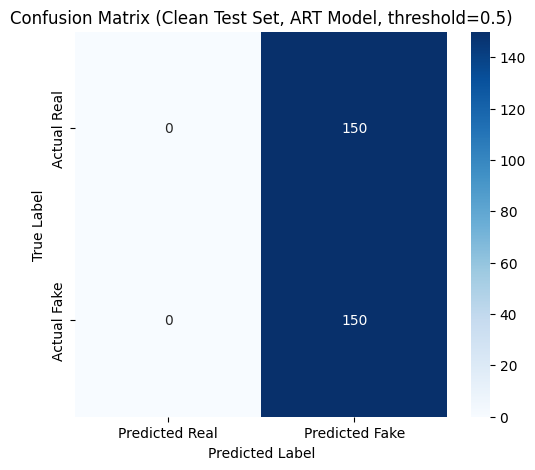

In [10]:
# ============================================================
# CELL 9: FINAL CLEAN TEST EVALUATION [NEW]
# ============================================================
# Uses test_loader exactly as before (never modified, never attacked here).
# Reports metrics at the default threshold (0.5) AND at the optimal
# threshold found via Youden's J statistic, matching the existing
# notebook's evaluation style.

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve, f1_score, accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_auc_score,
)


def _compute_metrics_at_threshold(all_labels, all_preds, threshold):
    binary_preds = (all_preds >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(all_labels, binary_preds),
        "precision_macro": precision_score(all_labels, binary_preds, average="macro", zero_division=0),
        "recall_macro": recall_score(all_labels, binary_preds, average="macro", zero_division=0),
        "f1_macro": f1_score(all_labels, binary_preds, average="macro", zero_division=0),
        "precision_fake": precision_score(all_labels, binary_preds, pos_label=1, zero_division=0),
        "recall_fake": recall_score(all_labels, binary_preds, pos_label=1, zero_division=0),
        "f1_fake": f1_score(all_labels, binary_preds, pos_label=1, zero_division=0),
    }, binary_preds


def generate_final_report_art(model, dataloader, device, use_amp=USE_AMP):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for videos, labels in dataloader:
            videos = videos.to(device)
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(videos)
            else:
                logits = model(videos)
            preds = torch.sigmoid(logits).cpu().numpy()

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels).astype(int)

    try:
        roc_auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        roc_auc = 0.0

    # Optimal threshold via Youden's J statistic
    try:
        fpr, tpr, thresholds = roc_curve(all_labels, all_preds)
        j_scores = tpr - fpr
        optimal_idx = np.argmax(j_scores)
        optimal_threshold = float(thresholds[optimal_idx])
    except ValueError:
        optimal_threshold = 0.5

    default_metrics, default_bin_preds = _compute_metrics_at_threshold(all_labels, all_preds, 0.5)
    optimal_metrics, optimal_bin_preds = _compute_metrics_at_threshold(all_labels, all_preds, optimal_threshold)

    print("=" * 55)
    print("FINAL CLEAN TEST EVALUATION (ART-Trained Model)")
    print("=" * 55)

    print(f"\nROC-AUC (threshold-independent): {roc_auc:.4f}")

    print(f"\n--- Default Threshold = 0.5 ---")
    for k, v in default_metrics.items():
        print(f"  {k:<18}: {v:.4f}")

    print(f"\n--- Optimal Threshold (Youden's J) = {optimal_threshold:.4f} ---")
    for k, v in optimal_metrics.items():
        print(f"  {k:<18}: {v:.4f}")

    print("\n=== CLASSIFICATION REPORT (default threshold = 0.5) ===")
    print(classification_report(all_labels, default_bin_preds, target_names=['Real', 'Fake']))

    # Confusion matrix (default threshold, matching existing notebook style)
    cm = confusion_matrix(all_labels, default_bin_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Predicted Real', 'Predicted Fake'],
                yticklabels=['Actual Real', 'Actual Fake'])
    plt.title('Confusion Matrix (Clean Test Set, ART Model, threshold=0.5)')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

    return {
        "roc_auc": roc_auc,
        "optimal_threshold": optimal_threshold,
        "default_threshold_metrics": default_metrics,
        "optimal_threshold_metrics": optimal_metrics,
        "raw_preds": all_preds,
        "raw_labels": all_labels,
    }


clean_test_results = generate_final_report_art(model, test_loader, CONFIG["device"])


In [11]:
# ============================================================
# CELL 10: FGSM ROBUSTNESS TEST [NEW]
# ============================================================
# Evaluates the final ART model against FGSM attacks of increasing strength
# on test_loader. This is evaluation-only: test data is never used for
# training and no weights are updated here.

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
from tqdm.notebook import tqdm


def evaluate_attack_on_loader(model, dataloader, device, attack_fn, use_amp=USE_AMP):
    """
    Generic evaluator: attack_fn(model, videos, labels) -> adv_videos (or None for clean).
    Returns dict of accuracy/precision/recall/f1/roc_auc.
    """
    model.eval()
    all_preds, all_labels = [], []

    for videos, labels in tqdm(dataloader, desc="Evaluating attack", leave=False):
        videos = videos.to(device, non_blocking=True)
        labels_dev = labels.to(device, non_blocking=True)

        if attack_fn is not None:
            eval_videos = attack_fn(model, videos, labels_dev)
        else:
            eval_videos = videos

        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(eval_videos)
            else:
                logits = model(eval_videos)
            preds = torch.sigmoid(logits).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels).astype(int)
    binary_preds = (all_preds >= 0.5).astype(int)

    try:
        roc_auc = roc_auc_score(all_labels, all_preds)
    except ValueError:
        roc_auc = 0.0

    return {
        "accuracy": accuracy_score(all_labels, binary_preds),
        "precision": precision_score(all_labels, binary_preds, average="macro", zero_division=0),
        "recall": recall_score(all_labels, binary_preds, average="macro", zero_division=0),
        "f1": f1_score(all_labels, binary_preds, average="macro", zero_division=0),
        "roc_auc": roc_auc,
    }


fgsm_epsilons_px = [2 / 255, 4 / 255, 8 / 255]
fgsm_robustness_rows = []

# Clean baseline (epsilon = 0)
clean_metrics = evaluate_attack_on_loader(model, test_loader, CONFIG["device"], attack_fn=None)
fgsm_robustness_rows.append({"Attack": "Clean", "Epsilon": 0.0, **clean_metrics})

for eps in fgsm_epsilons_px:
    attack_fn = lambda m, v, l, eps=eps: fgsm_attack(m, v, l, epsilon=eps, criterion=criterion)
    metrics = evaluate_attack_on_loader(model, test_loader, CONFIG["device"], attack_fn=attack_fn)
    fgsm_robustness_rows.append({"Attack": "FGSM", "Epsilon": eps, **metrics})

fgsm_robustness_df = pd.DataFrame(fgsm_robustness_rows)
fgsm_robustness_df["Epsilon (frac)"] = fgsm_robustness_df["Epsilon"].apply(
    lambda e: "0" if e == 0 else f"{round(e * 255)}/255"
)

print("FGSM Robustness Test Results")
print(fgsm_robustness_df[["Attack", "Epsilon (frac)", "accuracy", "precision", "recall", "f1", "roc_auc"]]
      .to_string(index=False))


Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

FGSM Robustness Test Results
Attack Epsilon (frac)  accuracy  precision  recall       f1  roc_auc
 Clean              0       0.5       0.25     0.5 0.333333 0.537311
  FGSM          2/255       0.5       0.25     0.5 0.333333 0.013378
  FGSM          4/255       0.5       0.25     0.5 0.333333 0.048511
  FGSM          8/255       0.5       0.25     0.5 0.333333 0.155178


In [12]:
# ============================================================
# CELL 11: PGD ROBUSTNESS TEST [NEW]
# ============================================================
# PGD is used ONLY for evaluation (never for training) to keep Kaggle
# runtime practical, since EfficientNet-B1 + LSTM is expensive to run
# through multiple attack iterations per batch.

import numpy as np
import pandas as pd

pgd_robustness_rows = []

# --- PGD-3: epsilon=4/255, alpha=1/255, steps=3 ---
pgd3_attack_fn = lambda m, v, l: pgd_attack(
    m, v, l, epsilon=4 / 255, alpha=1 / 255, steps=3, criterion=criterion
)
pgd3_metrics = evaluate_attack_on_loader(model, test_loader, CONFIG["device"], attack_fn=pgd3_attack_fn)
pgd_robustness_rows.append({"Attack": "PGD-3", "Epsilon": 4 / 255, "Steps": 3, **pgd3_metrics})

# --- PGD-5 (optional, stronger): epsilon=4/255, alpha=1/255, steps=5 ---
pgd5_attack_fn = lambda m, v, l: pgd_attack(
    m, v, l, epsilon=4 / 255, alpha=1 / 255, steps=5, criterion=criterion
)
pgd5_metrics = evaluate_attack_on_loader(model, test_loader, CONFIG["device"], attack_fn=pgd5_attack_fn)
pgd_robustness_rows.append({"Attack": "PGD-5", "Epsilon": 4 / 255, "Steps": 5, **pgd5_metrics})

pgd_robustness_df = pd.DataFrame(pgd_robustness_rows)

# Pull the Clean and FGSM(4/255) rows already computed in Cell 10 for a combined view
clean_row = fgsm_robustness_df[fgsm_robustness_df["Attack"] == "Clean"].iloc[0]
fgsm4_row = fgsm_robustness_df[
    (fgsm_robustness_df["Attack"] == "FGSM") & (np.isclose(fgsm_robustness_df["Epsilon"], 4 / 255))
].iloc[0]

print("Clean vs FGSM vs PGD Summary")
print(f"{'Condition':<12}{'Accuracy':>10}{'Precision':>12}{'Recall':>10}{'F1':>10}{'ROC-AUC':>10}")
for label, row in [
    ("Clean", clean_row),
    ("FGSM 4/255", fgsm4_row),
    ("PGD-3 4/255", pgd_robustness_df.iloc[0]),
    ("PGD-5 4/255", pgd_robustness_df.iloc[1]),
]:
    print(f"{label:<12}{row['accuracy']:>10.4f}{row['precision']:>12.4f}{row['recall']:>10.4f}"
          f"{row['f1']:>10.4f}{row['roc_auc']:>10.4f}")

print("\nPGD Robustness Test Results")
print(pgd_robustness_df[["Attack", "Steps", "accuracy", "precision", "recall", "f1", "roc_auc"]]
      .to_string(index=False))


Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Clean vs FGSM vs PGD Summary
Condition     Accuracy   Precision    Recall        F1   ROC-AUC
Clean           0.5000      0.2500    0.5000    0.3333    0.5373
FGSM 4/255      0.5000      0.2500    0.5000    0.3333    0.0485
PGD-3 4/255     0.5000      0.2500    0.5000    0.3333    0.0000
PGD-5 4/255     0.4933      0.2483    0.4933    0.3304    0.0000

PGD Robustness Test Results
Attack  Steps  accuracy  precision   recall       f1  roc_auc
 PGD-3      3  0.500000   0.250000 0.500000 0.333333      0.0
 PGD-5      5  0.493333   0.248322 0.493333 0.330357      0.0


In [13]:
# ============================================================
# CELL 12: ROBUSTNESS COMPARISON [NEW]
# ============================================================
# Combines Clean / FGSM(2,4,8 / 255) / PGD-3(4/255) results from Cells 10-11
# into one comparison table with Accuracy Drop and Robustness Retention,
# demonstrating whether ART actually improved robustness.

import pandas as pd

comparison_rows = []

clean_acc_ref = fgsm_robustness_df.loc[fgsm_robustness_df["Attack"] == "Clean", "accuracy"].iloc[0]

for _, row in fgsm_robustness_df.iterrows():
    if row["Attack"] == "Clean":
        label = "Clean"
    else:
        label = f"FGSM {round(row['Epsilon'] * 255)}/255"
    acc = row["accuracy"]
    comparison_rows.append({
        "Model / Condition": label,
        "Accuracy": acc,
        "Precision": row["precision"],
        "Recall": row["recall"],
        "F1": row["f1"],
        "ROC-AUC": row["roc_auc"],
        "Accuracy Drop": clean_acc_ref - acc,
        "Robustness Retention (%)": (acc / clean_acc_ref * 100.0) if clean_acc_ref > 0 else 0.0,
    })

pgd3_row = pgd_robustness_df[pgd_robustness_df["Attack"] == "PGD-3"].iloc[0]
comparison_rows.append({
    "Model / Condition": "PGD-3 4/255",
    "Accuracy": pgd3_row["accuracy"],
    "Precision": pgd3_row["precision"],
    "Recall": pgd3_row["recall"],
    "F1": pgd3_row["f1"],
    "ROC-AUC": pgd3_row["roc_auc"],
    "Accuracy Drop": clean_acc_ref - pgd3_row["accuracy"],
    "Robustness Retention (%)": (pgd3_row["accuracy"] / clean_acc_ref * 100.0) if clean_acc_ref > 0 else 0.0,
})

robustness_comparison_df = pd.DataFrame(comparison_rows)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("Robustness Comparison Table")
print(robustness_comparison_df.to_string(index=False))


Robustness Comparison Table
Model / Condition  Accuracy  Precision  Recall     F1  ROC-AUC  Accuracy Drop  Robustness Retention (%)
            Clean    0.5000     0.2500  0.5000 0.3333   0.5373         0.0000                  100.0000
       FGSM 2/255    0.5000     0.2500  0.5000 0.3333   0.0134         0.0000                  100.0000
       FGSM 4/255    0.5000     0.2500  0.5000 0.3333   0.0485         0.0000                  100.0000
       FGSM 8/255    0.5000     0.2500  0.5000 0.3333   0.1552         0.0000                  100.0000
      PGD-3 4/255    0.5000     0.2500  0.5000 0.3333   0.0000         0.0000                  100.0000


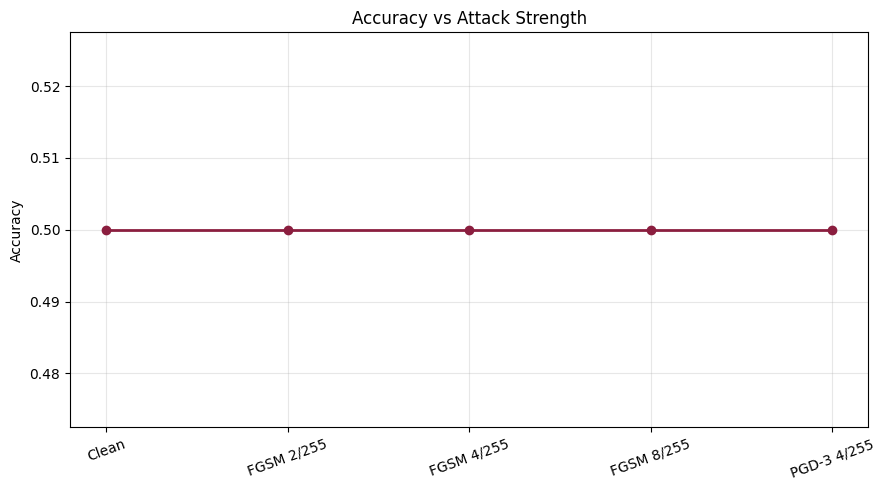

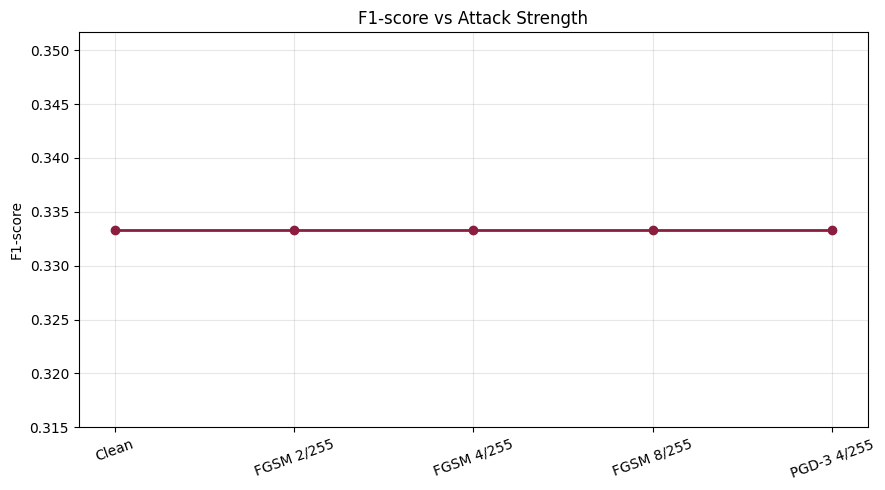

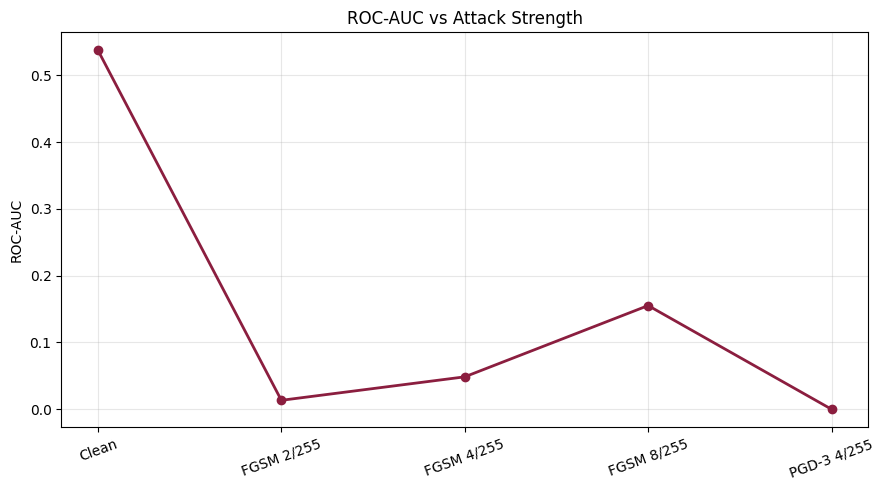

Saved plots to /kaggle/working/: robustness_accuracy.png, robustness_f1.png, robustness_auc.png


In [14]:
# ============================================================
# CELL 13: ROBUSTNESS VISUALIZATION [NEW]
# ============================================================

import matplotlib.pyplot as plt

labels_x = robustness_comparison_df["Model / Condition"].tolist()
x_positions = range(len(labels_x))


def _plot_metric(metric_col, ylabel, title, out_path):
    plt.figure(figsize=(9, 5))
    plt.plot(x_positions, robustness_comparison_df[metric_col], marker="o", linewidth=2, color="#8B1E3F")
    plt.xticks(list(x_positions), labels_x, rotation=20)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()


_plot_metric("Accuracy", "Accuracy", "Accuracy vs Attack Strength", "/kaggle/working/robustness_accuracy.png")
_plot_metric("F1", "F1-score", "F1-score vs Attack Strength", "/kaggle/working/robustness_f1.png")
_plot_metric("ROC-AUC", "ROC-AUC", "ROC-AUC vs Attack Strength", "/kaggle/working/robustness_auc.png")

print("Saved plots to /kaggle/working/: robustness_accuracy.png, robustness_f1.png, robustness_auc.png")


True label               : real
Clean prediction         : fake (confidence 0.8361)
Adversarial prediction   : fake (confidence 0.8358)


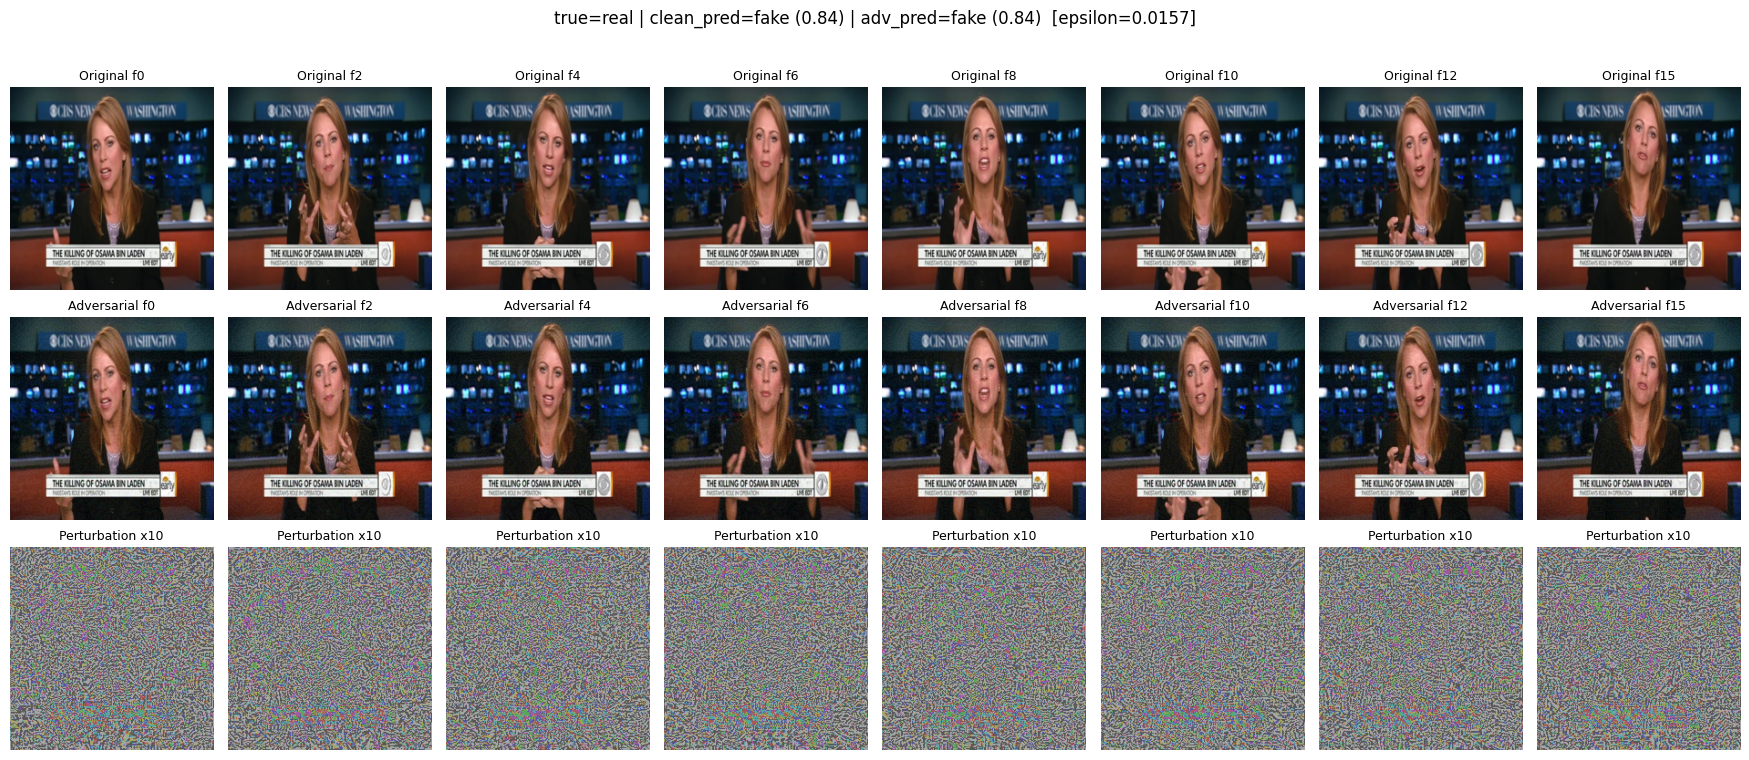

In [15]:
# ============================================================
# CELL 14: ADVERSARIAL EXAMPLE VISUALIZATION [NEW]
# ============================================================
# Shows Original / Adversarial / Perturbation x10 for several frames of one
# test video. The amplified perturbation is for DISPLAY ONLY and is never
# fed back into the model.

import torch
import numpy as np
import matplotlib.pyplot as plt

NUM_FRAMES_TO_SHOW = 8

sample_video, sample_label = test_dataset[0]
sample_video = sample_video.unsqueeze(0).to(CONFIG["device"])       # [1, T, 3, 224, 224]
sample_label_tensor = sample_label.unsqueeze(0).to(CONFIG["device"])  # [1]

model.eval()

with torch.no_grad():
    clean_logits = model(sample_video)
    clean_prob_fake = torch.sigmoid(clean_logits).item()

adv_video = fgsm_attack(
    model, sample_video, sample_label_tensor,
    epsilon=CONFIG["adv_eval_epsilon"], criterion=criterion
)

with torch.no_grad():
    adv_logits = model(adv_video)
    adv_prob_fake = torch.sigmoid(adv_logits).item()

true_label_str = "fake" if int(sample_label.item()) == 1 else "real"
clean_pred_str = "fake" if clean_prob_fake >= 0.5 else "real"
adv_pred_str = "fake" if adv_prob_fake >= 0.5 else "real"
clean_conf = clean_prob_fake if clean_pred_str == "fake" else 1 - clean_prob_fake
adv_conf = adv_prob_fake if adv_pred_str == "fake" else 1 - adv_prob_fake

print(f"True label               : {true_label_str}")
print(f"Clean prediction         : {clean_pred_str} (confidence {clean_conf:.4f})")
print(f"Adversarial prediction   : {adv_pred_str} (confidence {adv_conf:.4f})")

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

total_frames = sample_video.shape[1]
frame_indices = np.linspace(0, total_frames - 1, NUM_FRAMES_TO_SHOW, dtype=int)

fig, axes = plt.subplots(3, NUM_FRAMES_TO_SHOW, figsize=(2.2 * NUM_FRAMES_TO_SHOW, 7.5))
fig.suptitle(
    f"true={true_label_str} | clean_pred={clean_pred_str} ({clean_conf:.2f}) | "
    f"adv_pred={adv_pred_str} ({adv_conf:.2f})  [epsilon={CONFIG['adv_eval_epsilon']:.4f}]",
    fontsize=12, y=1.02
)

for i, f_idx in enumerate(frame_indices):
    clean_frame = sample_video[0, f_idx].detach().cpu().numpy().transpose(1, 2, 0)
    adv_frame = adv_video[0, f_idx].detach().cpu().numpy().transpose(1, 2, 0)

    clean_pixel = np.clip(std * clean_frame + mean, 0, 1)
    adv_pixel = np.clip(std * adv_frame + mean, 0, 1)

    # Amplify the perturbation only for display; never used as model input.
    perturbation = adv_pixel - clean_pixel
    perturbation_amplified = np.clip(perturbation * 10 + 0.5, 0, 1)

    axes[0, i].imshow(clean_pixel)
    axes[0, i].set_title(f"Original f{f_idx}", fontsize=9)
    axes[0, i].axis("off")

    axes[1, i].imshow(adv_pixel)
    axes[1, i].set_title(f"Adversarial f{f_idx}", fontsize=9)
    axes[1, i].axis("off")

    axes[2, i].imshow(perturbation_amplified)
    axes[2, i].set_title("Perturbation x10", fontsize=9)
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()


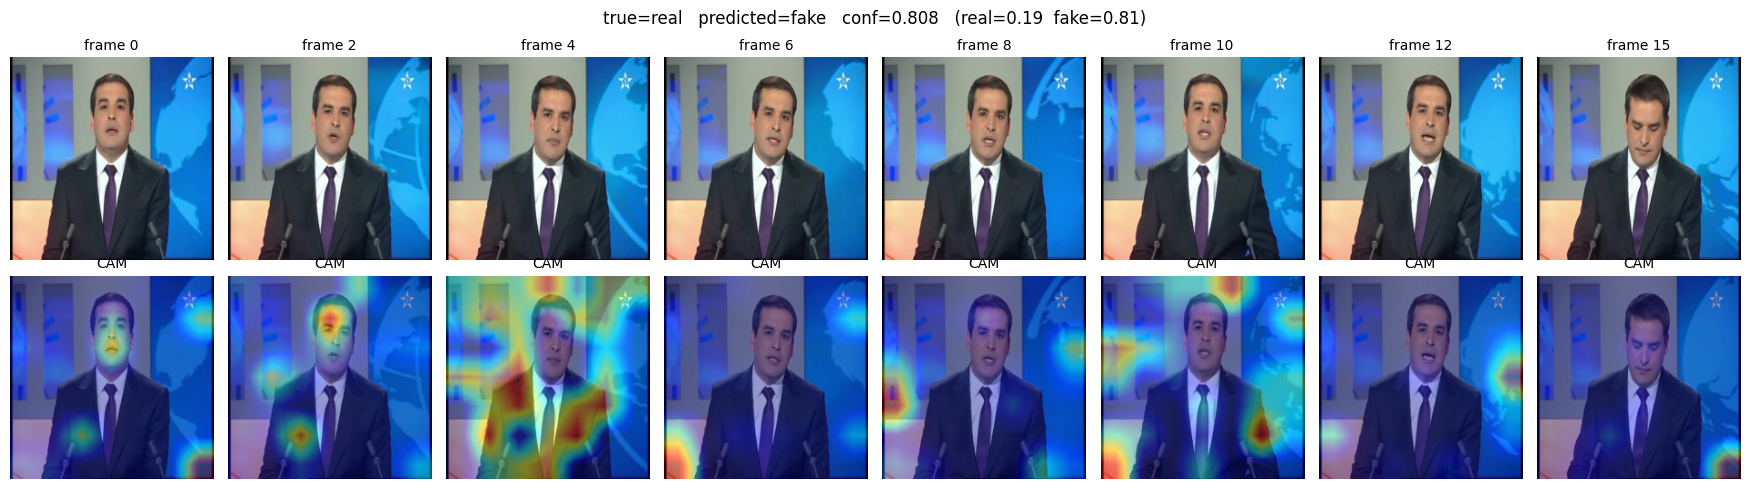

In [16]:
# ============================================================
# CELL 15: GRAD-CAM (ART-TRAINED MODEL) [UPDATED]
# ============================================================
# Keeps the existing VideoGradCAM implementation and target layer
# unchanged. Explicitly (re)loads the best ART checkpoint before
# generating heatmaps, so this cell is correct even if run standalone.

import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

class VideoGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Register modern hooks (prevents PyTorch deprecation warnings)
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output.detach()
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
        
    def generate_heatmaps_all_frames(self, video_tensor):
        """
        Generates GradCAM heatmaps for ALL frames in the input video tensor sequence.
        video_tensor shape: (1, seq_len, 3, 224, 224)
        Returns: logits, probability score, and heatmaps numpy array of shape (seq_len, H, W)
        """
        was_training = self.model.training
        
        # Force model to train mode during backward pass so cuDNN RNN handles backward computation
        self.model.train()
        
        # Forward pass
        logits = self.model(video_tensor)
        prob = torch.sigmoid(logits).item()
        
        # Backward pass for gradients
        self.model.zero_grad()
        logits.backward()
        
        # self.gradients and self.activations have shape: (seq_len, C, H, W)
        grads = self.gradients
        acts = self.activations
        
        # Global average pooling of gradients per frame
        weights = torch.mean(grads, dim=(2, 3), keepdim=True) # Shape: (seq_len, C, 1, 1)
        
        # Weighted combination of activation maps
        cams = torch.sum(weights * acts, dim=1) # Shape: (seq_len, H, W)
        cams = F.relu(cams) # Isolated features positively contributing to score
        
        # Normalize each frame's heatmap individually
        heatmaps = []
        for i in range(cams.size(0)):
            cam = cams[i]
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-7)
            heatmaps.append(cam.cpu().numpy())

        if not was_training:
            self.model.eval()
            
        return logits, prob, np.array(heatmaps)


def visualize_gradcam_sequence(model, dataset, sample_idx=0, num_frames_to_display=8):
    # Target layer: EfficientNet-B1's final sequential block before pooling
    target_layer = model.feature_extractor[0][-1] 
    grad_cam = VideoGradCAM(model, target_layer)
    
    # Fetch sample data 
    video_tensor, true_label_idx = dataset[-1]
    true_label = "fake" if int(true_label_idx.item()) == 1 else "real"
    
    # Add batch dimension and enable gradients
    video_tensor_input = video_tensor.unsqueeze(0).to(CONFIG["device"])
    video_tensor_input.requires_grad = True
    
    # Generate heatmaps for all frames
    _, fake_prob, heatmaps = grad_cam.generate_heatmaps_all_frames(video_tensor_input)
    
    real_prob = 1.0 - fake_prob
    pred_label = "fake" if fake_prob >= 0.5 else "real"
    conf = fake_prob if pred_label == "fake" else real_prob
    
    total_seq_len = video_tensor.size(0)
    
    # Select evenly spaced frame indices across the sequence
    frame_indices = np.linspace(0, total_seq_len - 1, num_frames_to_display, dtype=int)
    
    # De-normalize image constants
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    # Setup Figure Layout (2 Rows x N Columns)
    fig, axes = plt.subplots(2, num_frames_to_display, figsize=(2.2 * num_frames_to_display, 5))
    
    # Set top title matching the requested format
    fig.suptitle(
        f"true={true_label}   predicted={pred_label}   conf={conf:.3f}   (real={real_prob:.2f}  fake={fake_prob:.2f})",
        fontsize=12, y=0.98
    )

    for i, f_idx in enumerate(frame_indices):
        # 1. Reconstruct source RGB frame
        src_frame = video_tensor[f_idx].detach().cpu().numpy().transpose(1, 2, 0)
        src_frame = std * src_frame + mean
        src_frame = np.clip(src_frame, 0, 1)
        src_frame_uint8 = (src_frame * 255).astype(np.uint8)
        
        # 2. Resize heatmap and create overlay
        heatmap_resized = cv2.resize(heatmaps[f_idx], (CONFIG["img_size"], CONFIG["img_size"]))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
        
        overlay = cv2.addWeighted(src_frame_uint8, 0.6, heatmap_color, 0.4, 0)
        
        # --- Top Row: Original Frame with slight darkness/blend ---
        axes[0, i].imshow(src_frame)
        axes[0, i].set_title(f"frame {f_idx}", fontsize=10)
        axes[0, i].axis('off')
        
        # --- Bottom Row: CAM Overlay ---
        axes[1, i].imshow(overlay)
        axes[1, i].set_title("CAM", fontsize=10)
        axes[1, i].axis('off')
        
    plt.tight_layout()
    plt.show()

# Ensure we are visualizing the ART-trained checkpoint specifically.
# Load the checkpoint IN PLACE into the existing `model` object instead of
# instantiating a second FFPPDeepfakeDetector (see the memory note in Cell 8
# -- the same "two full models on the GPU at once" issue applies here).
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if "model" not in globals():
    model = FFPPDeepfakeDetector().to(CONFIG["device"])
model.load_state_dict(torch.load(CONFIG["save_adv_checkpoint"], map_location=CONFIG["device"]))
model.eval()

# Run the multi-frame Grad-CAM visualization using the ART-trained model
visualize_gradcam_sequence(model, test_dataset, sample_idx=0, num_frames_to_display=8)
